### 1.1. `plt.subplots` и `ax.plot`: первый график

Matplotlib строит графики из числовых данных. `Figure` — весь рисунок, `Axes` — отдельная область с координатами, `Axis` — конкретная ось X или Y. Объектный стиль явно показывает, на какой области рисуем.

**Как записывать**

```python
fig, ax = plt.subplots(figsize=(8, 4), dpi=100)
ax.plot(x, y, color="tab:blue", linestyle="-", marker="o", label="Ряд")
ax.set(xlabel="X", ylabel="Y", title="Название")
ax.legend()
plt.show()
plt.close(fig)
```

**Параметры и свойства**

- `figsize=(ширина, высота)` — размер рисунка в дюймах; `dpi` — пиксели на дюйм.
- `plot(x,y)` принимает значения X и Y одинаковой длины. Если передать только Y, X будут позициями 0…N−1.
- `color` — цвет, `linestyle` — `-`, `--`, `:`, `marker` — символ каждой точки.
- `label` — название ряда для легенды; сама легенда появляется после `.legend()`.
- `.set_xlabel`, `.set_ylabel`, `.set_title` задают подписи; `.set(...)` объединяет их.
- `show()` отображает рисунок, `close(fig)` освобождает его после отображения.

**Как это работает**

`plot` соединяет точки в порядке их передачи. На одной Axes можно несколько раз вызвать `plot` для нескольких рядов. Для сетки `.grid(alpha=0.2)` задаёт прозрачность. Числовой X для примера создадим `np.linspace(start,stop,num)`: num равномерных точек с включёнными границами.

**Частая ошибка:** Назвать ось переменной `ax` мало: читателю нужны её подпись и единицы. Линия между неупорядоченными наблюдениями может вводить в заблуждение — тогда нужен scatter.

**Пример**

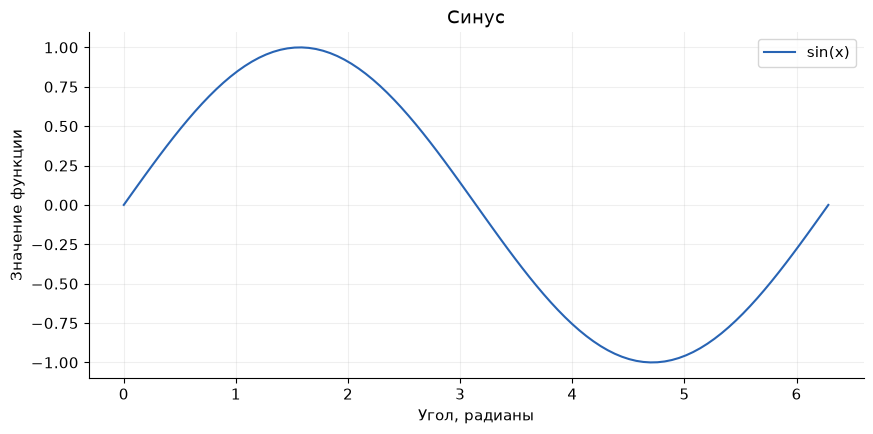

In [1]:
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
%matplotlib inline

plt.rcParams.update({'figure.figsize': (10, 4.5), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.2, 'figure.dpi': 100})
COLORS = ['#2864B4', '#B76B12', '#9860A8']
LINESTYLES = ['-', '--', ':']
pd.set_option('display.max_rows', 12)

x = np.linspace(0, 2*np.pi, 100)
fig, ax = plt.subplots()
ax.plot(x, np.sin(x), color=COLORS[0], label='sin(x)')
ax.set(xlabel='Угол, радианы', ylabel='Значение функции', title='Синус')
ax.legend()
plt.show()
plt.close(fig)

### Тренировка

На одной области нарисуй синус и косинус разными цветами и стилями линий. Добавь легенду и подписи.

<details><summary>Подсказка — открой после своей попытки</summary>

Вызови `ax.plot` дважды для одного `ax`.

</details>

In [2]:
# Твоё решение
# Напиши код здесь. Исходные данные и примеры выше можно использовать.

**Эталон и разбор.** Сначала сравни идею решения со своей, затем запусти ячейку ниже.

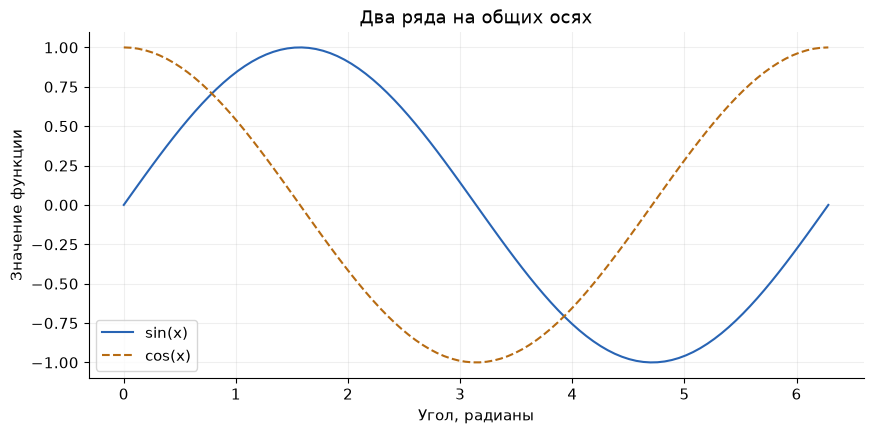

In [3]:
fig, ax = plt.subplots()
ax.plot(x, np.sin(x), color=COLORS[0], linestyle='-', label='sin(x)')
ax.plot(x, np.cos(x), color=COLORS[1], linestyle='--', label='cos(x)')
ax.set(xlabel='Угол, радианы', ylabel='Значение функции', title='Два ряда на общих осях')
ax.legend()
plt.show()
plt.close(fig)

**Что проверить и объяснить:** Различимость обеспечивают и цвет, и стиль линии. Какие две подписи помогают понять единицы?

### 1.2. Даты, локаторы и общие оси

Для временного ряда X должен содержать реальные даты. Локатор выбирает положение засечек, форматтер — надпись. Несколько областей с общей осью нужны для сравнения рядов в одинаковых диапазонах.

**Как записывать**

```python
dates = pd.date_range("2020-01-01", periods=24, freq="MS")
fig, axes = plt.subplots(2, 1, sharex=True, sharey=True, constrained_layout=True)
axes[0].plot(dates, values)
axes[-1].xaxis.set_major_locator(mdates.YearLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[-1].xaxis.set_minor_locator(mdates.MonthLocator())
```

**Параметры и свойства**

- `date_range(start, end=..., periods=..., freq=...)` создаёт календарь; `D` — день, `MS` — начало месяца.
- `subplots(nrows,ncols)` задаёт сетку; для нескольких областей возвращается массив Axes.
- `sharex`/`sharey` связывают диапазоны осей.
- `constrained_layout=True` распределяет место под подписи.
- `YearLocator()` — годовые засечки, `MonthLocator()` — месячные.
- `DateFormatter("%Y")` выводит год; `.set_xlim(start,end)` ограничивает показанный период.

**Как это работает**

В одной области `ax` — объект, при двух областях `axes[0]` и `axes[1]` — разные объекты. При `sharex=True` подписи общей оси X по умолчанию остаются на нижней области. Число дат должно совпадать с длиной Y.

**Частая ошибка:** Нельзя механически считать каждый год как 365 дней: високосный год меняет длину ряда.

**Пример**

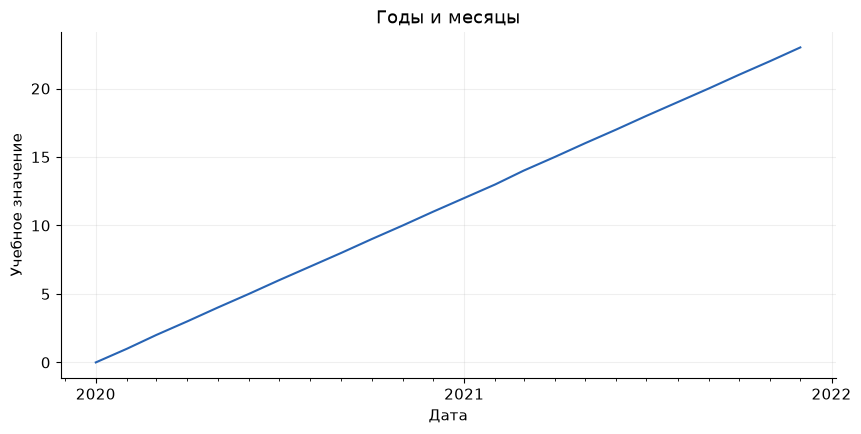

In [4]:
demo_dates = pd.date_range('2020-01-01', periods=24, freq='MS')
fig, ax = plt.subplots()
ax.plot(demo_dates, np.arange(24), color=COLORS[0])
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_minor_locator(mdates.MonthLocator())
ax.set(xlabel='Дата', ylabel='Учебное значение', title='Годы и месяцы')
plt.show()
plt.close(fig)

### Тренировка

Создай две области одна под другой с общей X. На первой — рост 0…23, на второй — спад 23…0 по тем же датам.

<details><summary>Подсказка — открой после своей попытки</summary>

Нужны `plt.subplots(2,1,sharex=True,sharey=True,constrained_layout=True)`.

</details>

In [5]:
# Твоё решение
# Напиши код здесь. Исходные данные и примеры выше можно использовать.

**Эталон и разбор.** Сначала сравни идею решения со своей, затем запусти ячейку ниже.

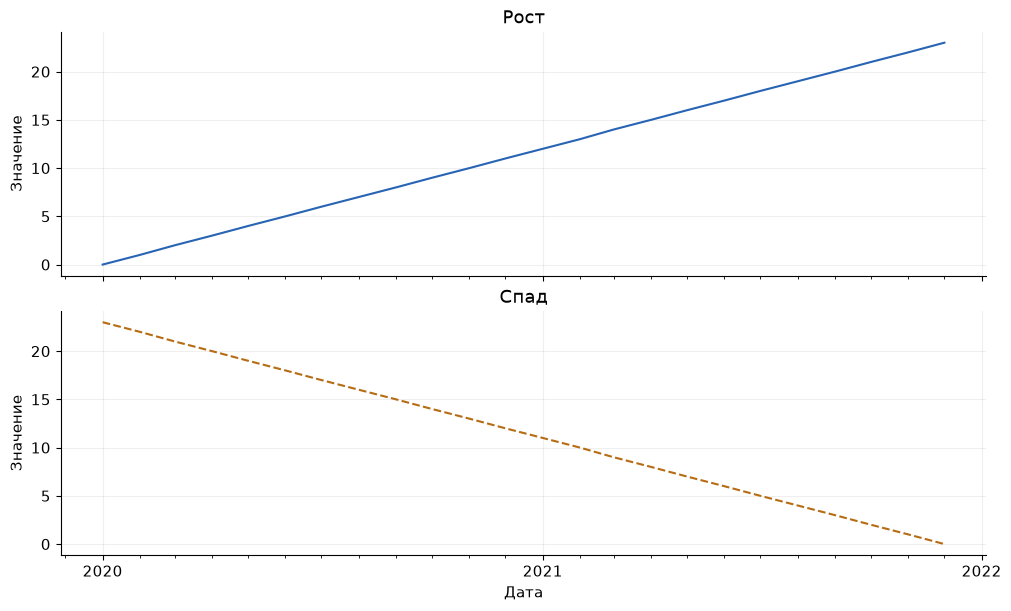

In [6]:
fig, axes = plt.subplots(2, 1, sharex=True, sharey=True, figsize=(10, 6), constrained_layout=True)
axes[0].plot(demo_dates, np.arange(24), color=COLORS[0])
axes[1].plot(demo_dates, np.arange(24)[::-1], color=COLORS[1], linestyle='--')
axes[0].set(title='Рост', ylabel='Значение')
axes[1].set(title='Спад', ylabel='Значение', xlabel='Дата')
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[1].xaxis.set_minor_locator(mdates.MonthLocator())
plt.show()
plt.close(fig)

**Что проверить и объяснить:** Подписи X есть только снизу, но диапазон X и Y общий. Это не две независимые шкалы.

### 1.3. `set_yscale` и горизонтальный порог

Логарифмическая шкала помогает видеть относительные изменения и величины разных порядков. Например, спад с 1000 до 100 и со 100 до 10 занимает одинаковое расстояние на log-оси.

**Как записывать**

```python
ax.set_yscale("log")
ax.axhline(100, color="red", linestyle="--", label="Порог")
ax.annotate("Порог 100", xy=(60,100), xytext=(0,7), textcoords="offset points")
```

**Параметры и свойства**

- `set_yscale("linear")` — обычная шкала; `"log"` — логарифмическая.
- `axhline(y)` рисует горизонтальную линию на уровне y.
- `annotate(text, xy, xytext, textcoords)` задаёт текст, точку привязки и смещение.
- `xycoords="axes fraction"` трактует координаты от 0 до 1 внутри области.
- `sharey=True` не применяй, если одна ось должна быть linear, другая log.

**Как это работает**

В данные ничего не записывается: масштаб меняет только положение значений на рисунке. Для log нужны положительные значения. Горизонтальный порог всегда остаётся на том же численном Y, даже если его визуальное положение отличается.

**Частая ошибка:** Нули и отрицательные числа не отображаются на обычной log-оси. Подпись формулы около линии не означает, что модель была подобрана к данным.

**Пример**

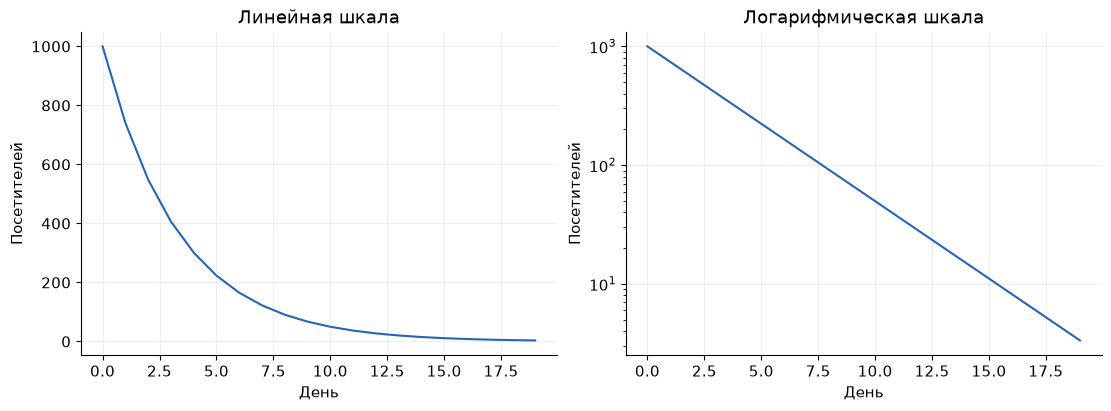

In [7]:
demo_days = np.arange(20)
demo_visitors = 1000 * np.exp(-0.3 * demo_days)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].plot(demo_days, demo_visitors, color=COLORS[0])
axes[1].plot(demo_days, demo_visitors, color=COLORS[0])
axes[1].set_yscale('log')
axes[0].set(title='Линейная шкала', xlabel='День', ylabel='Посетителей')
axes[1].set(title='Логарифмическая шкала', xlabel='День', ylabel='Посетителей')
plt.show()
plt.close(fig)

### Тренировка

Добавь к обоим графикам горизонтальную линию 100 и подпись порога.

<details><summary>Подсказка — открой после своей попытки</summary>

`ax.axhline(100,...)`, затем `ax.annotate`. Координаты текста удобнее задавать относительными долями области.

</details>

In [8]:
# Твоё решение
# Напиши код здесь. Исходные данные и примеры выше можно использовать.

**Эталон и разбор.** Сначала сравни идею решения со своей, затем запусти ячейку ниже.

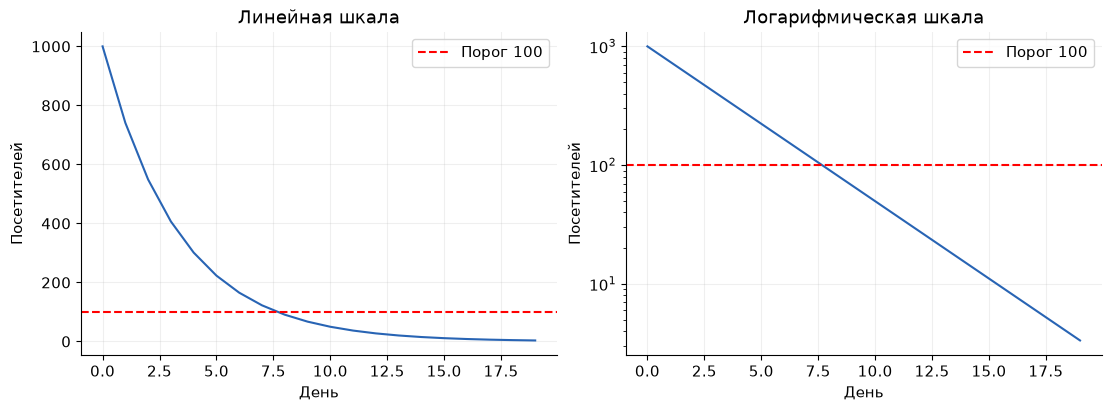

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax in axes:
    ax.plot(demo_days, demo_visitors, color=COLORS[0])
    ax.axhline(100, color='red', linestyle='--', label='Порог 100')
    ax.set(xlabel='День', ylabel='Посетителей')
    ax.legend()
axes[0].set_title('Линейная шкала')
axes[1].set_title('Логарифмическая шкала')
axes[1].set_yscale('log')
plt.show()
plt.close(fig)

**Что проверить и объяснить:** Почему экспонента на логарифмической оси похожа на прямую? Здесь циклы для оформления графиков разрешены.

In [10]:
from pathlib import Path
from IPython.display import display
# Найти исходные данные относительно текущей папки.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if all((p / folder).is_dir() for folder in ('01','02','03')))


## Лабораторная: Matplotlib, задания 1–4

В этом блоке графики создаются только вызовами Matplotlib. NumPy читает массивы, Pandas строит календарь дат — эти операции не являются визуализацией.

### ЛР5 · задание 1

1\. В файле `average_ratings.npy` содержится информация о среднем рейтинге 3 рецептов за период с 01.01.2019 по 30.12.2021. При помощи пакета `matplotlib` в _одной системе координат_ (на одной картинке) изобразите три временных ряда, соответствующих средним рейтингам этих рецептов. 

По горизонтальной оси располагается номер дня (0, 1, 2, ...), по вертикальной - средний рейтинг рецептов в этот день. 

Названия рецептов и их индексы в файле `average_ratings.npy`:
```
0: waffle iron french toast
1: zwetschgenkuchen bavarian plum cake
2: lime tea
```

Результатом работы является визуализация, на которой:
* добавлена подпись горизонтальной оси с текстом "Номер дня"
* добавлена подпись вертикальной оси с текстом "Средний рейтинг"
* добавлена подпись рисунка с текстом "Изменение среднего рейтинга трех рецептов"
* каждый из временных рядов имеет уникальный цвет
* добавлена легенда, на которой отображается название каждого из рецептов

_Примечание_ : для считывания файла воспользуйтесь функцией `np.load`.

<details><summary>Подсказка — открой после своей попытки</summary>

Массив имеет форму `(3,1095)`: первая ось — рецепты, вторая — дни.

</details>

In [11]:
# Твоё решение
# Напиши код здесь. Исходные данные и примеры выше можно использовать.

**Эталон и разбор.** Сначала сравни идею решения со своей, затем запусти ячейку ниже.

Форма данных: (3, 1095)


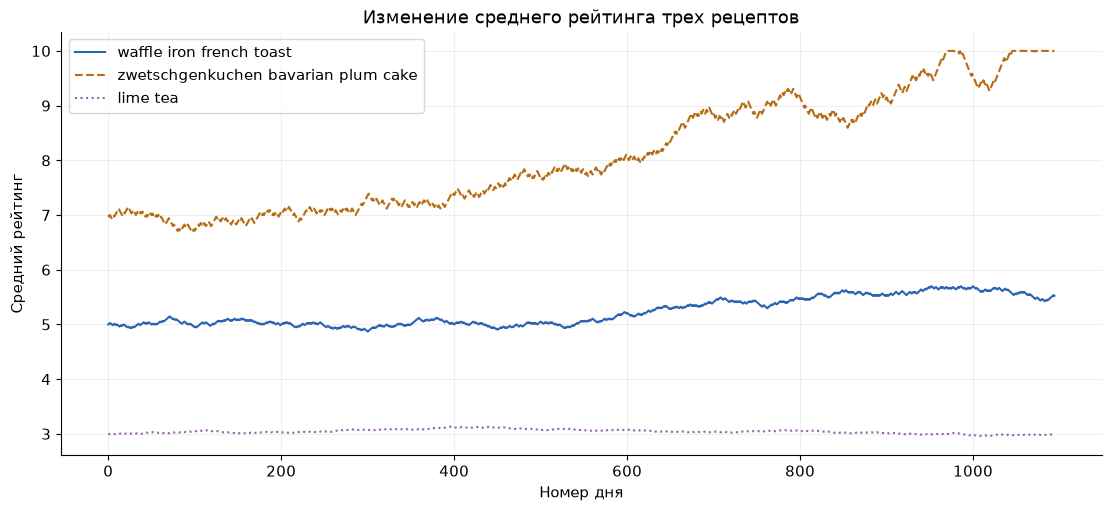

In [12]:
average_ratings = np.load(ROOT / '03/average_ratings.npy', allow_pickle=False)
recipe_names = ['waffle iron french toast', 'zwetschgenkuchen bavarian plum cake', 'lime tea']
assert average_ratings.shape[0] == len(recipe_names)
days = np.arange(average_ratings.shape[1])
print('Форма данных:', average_ratings.shape)
fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
for series, name, color, style in zip(average_ratings, recipe_names, COLORS, LINESTYLES):
    ax.plot(days, series, label=name, color=color, linestyle=style)
ax.set(xlabel='Номер дня', ylabel='Средний рейтинг', title='Изменение среднего рейтинга трех рецептов')
ax.legend(loc='upper left')
plt.show()
plt.close(fig)

**Что проверить и объяснить:** Три линии на одной области; ID 0,1,2 соответствует строкам, не столбцам. В локальном массиве рейтинг доходит до 10 — не ограничивай Y до 5 по аналогии с отзывами CSV.

### ЛР5 · задание 2

2\. Измените визуализацию, полученную в задании 1, таким образом, чтобы по горизонтальной оси отображались года, а между двумя соседними годами располагались засечки, соответствующие месяцам. Для этого создайте диапазон дат от 01.01.2019 по 30.12.2021 с шагом в один день (например, [вот так](https://pandas.pydata.org/docs/reference/api/pandas.date_range.html)) и используйте этот диапазон при вызове метода `plot`. Далее настройте `major_locator` и `minor_locator` горизонтальной оси (подробнее см. [здесь](https://matplotlib.org/stable/gallery/text_labels_and_annotations/date.html))

Примените к получившемуся рисунку цвета графиков, подписи, легенду из задания 1. Измените подпись горизонтальной оси, написав там слово "Дата".


<details><summary>Подсказка — открой после своей попытки</summary>

Создай ежедневные даты от 2019-01-01 до 2021-12-30 включительно, затем проверь длину.

</details>

In [13]:
# Твоё решение
# Напиши код здесь. Исходные данные и примеры выше можно использовать.

**Эталон и разбор.** Сначала сравни идею решения со своей, затем запусти ячейку ниже.

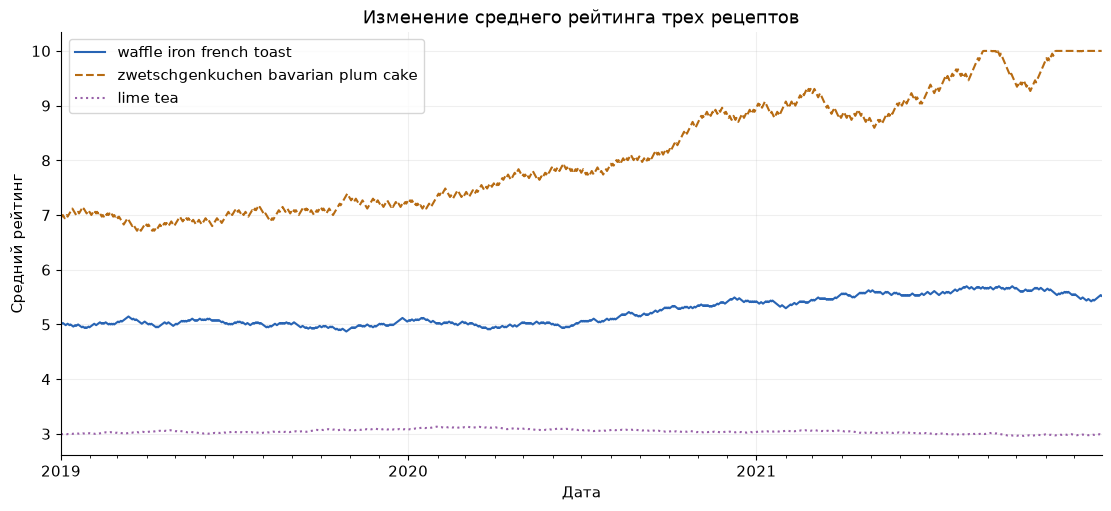

In [14]:
dates = pd.date_range('2019-01-01', '2021-12-30', freq='D')
assert len(dates) == average_ratings.shape[1]
fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
for series, name, color, style in zip(average_ratings, recipe_names, COLORS, LINESTYLES):
    ax.plot(dates, series, label=name, color=color, linestyle=style)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_minor_locator(mdates.MonthLocator())
ax.set_xlim(dates[0], dates[-1])
ax.set(xlabel='Дата', ylabel='Средний рейтинг', title='Изменение среднего рейтинга трех рецептов')
ax.legend(loc='upper left')
plt.show()
plt.close(fig)

**Что проверить и объяснить:** 1095 дат: 2020 год високосный, последняя дата — 30 декабря 2021. Нельзя просто брать 3*365 без проверки календаря.

### ЛР5 · задание 3

3\. Измените визуализацию, полученную в задании 2, разбив одну картинку на три, расположенных друг под другом. Три изображения должны иметь одну общую горизонтальную ось (каждое изображение засечки в нижней части, но значения этих засечек находятся только под самым нижним изображением). Примените к получившемуся рисунку цвета графиков, подписи, легенду из задания 2. 

<details><summary>Подсказка — открой после своей попытки</summary>

Три вертикальных subplots с `sharex=True`; общий масштаб Y полезен для сравнения рейтингов.

</details>

In [15]:
# Твоё решение
# Напиши код здесь. Исходные данные и примеры выше можно использовать.

**Эталон и разбор.** Сначала сравни идею решения со своей, затем запусти ячейку ниже.

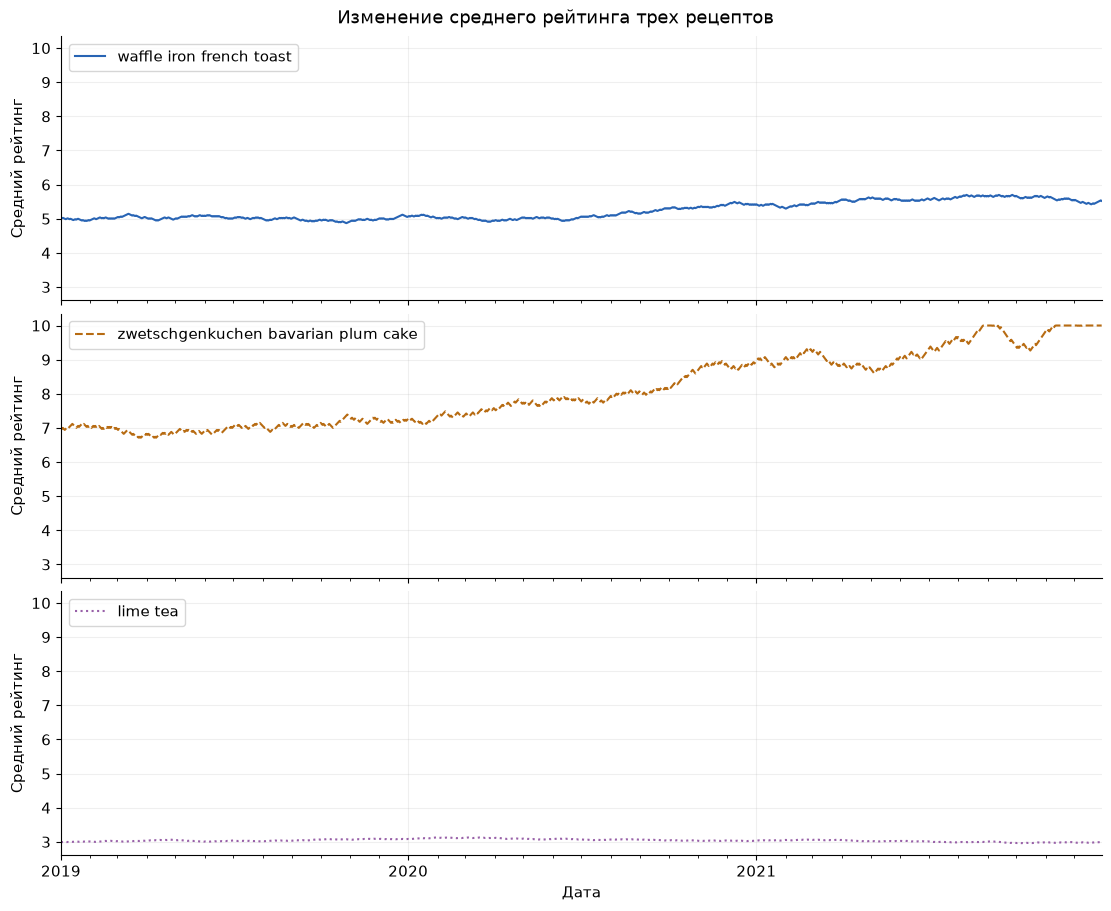

In [16]:
fig, axes = plt.subplots(3, 1, sharex=True, sharey=True, figsize=(11, 9), constrained_layout=True)
for ax, series, name, color, style in zip(axes, average_ratings, recipe_names, COLORS, LINESTYLES):
    ax.plot(dates, series, label=name, color=color, linestyle=style)
    ax.set_ylabel('Средний рейтинг')
    ax.legend(loc='upper left')
    ax.tick_params(axis='x', which='both', bottom=True)
axes[-1].xaxis.set_major_locator(mdates.YearLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[-1].xaxis.set_minor_locator(mdates.MonthLocator())
axes[-1].set_xlim(dates[0], dates[-1])
axes[-1].set_xlabel('Дата')
fig.suptitle('Изменение среднего рейтинга трех рецептов')
plt.show()
plt.close(fig)

**Что проверить и объяснить:** Сравни уровни рейтинга по общему Y. Отличай форму линии от её абсолютного уровня.

### ЛР5 · задание 4

4\. В файле `visitors.npy` представлена информация о количестве посетителей сайта в течении первых 100 дней после объявления сайтом акции. Постройте график изменения количества пользователей в зависимости от дня в двух вариантах, расположенных рядом по горизонтале. В обоих случаях изобразите график в виде ломаной, но в первом случае оставьте линейный масштаб осей, а во втором случае сделайте вертикальную ось в логарифмическом масштабе. Добавьте на обе картинки подпись над этим графиком к текстом $y(x)=\lambda e^{-\lambda x}$

Добавьте на оба изображения красную горизонтальную линию на уровне $y=100$. Добавьте на обе картинки подпись над этой линией с текстом $y(x)=100$

Добавьте на оба изображения подписи осей; горизонтальную ось подпишите текстом "Количество дней с момента акции", вертикальную - "Число посетителей".

Добавьте общий заголовок для фигуры с текстом "Изменение количества пользователей в линейном и логарифмическом масштабе".


<details><summary>Подсказка — открой после своей попытки</summary>

Загрузи visitors, проверь положительность и создай два графика одних данных. Формула — подпись из условия, параметры не оценены.

</details>

In [17]:
# Твоё решение
# Напиши код здесь. Исходные данные и примеры выше можно использовать.

**Эталон и разбор.** Сначала сравни идею решения со своей, затем запусти ячейку ниже.

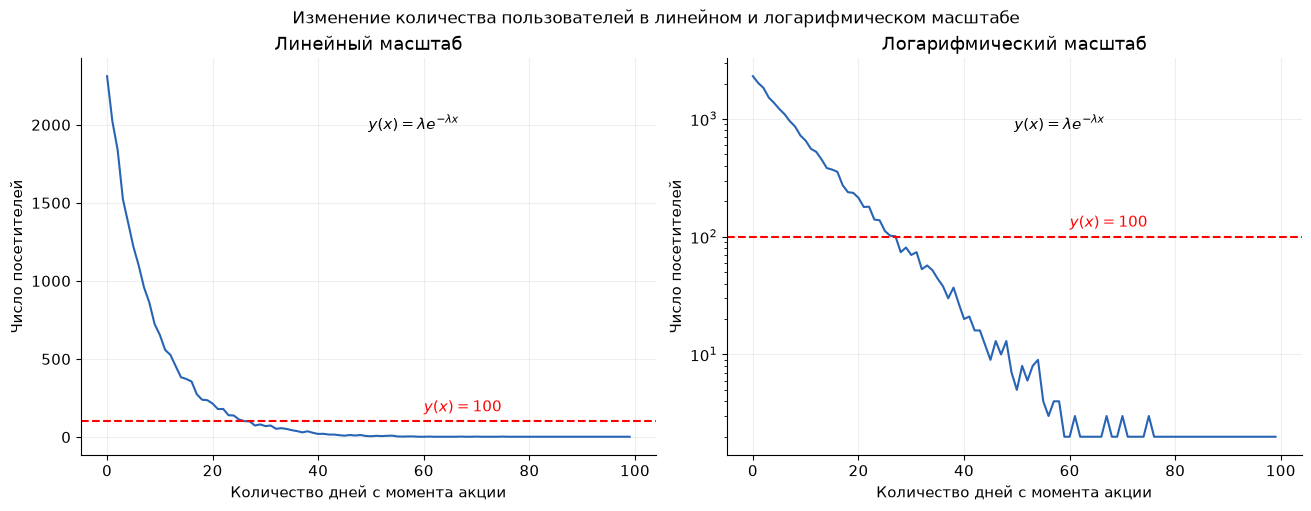

In [18]:
visitors = np.load(ROOT / '03/visitors.npy', allow_pickle=False)
assert visitors.shape == (100,) and (visitors > 0).all()
visitor_days = np.arange(len(visitors))
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax in axes:
    ax.plot(visitor_days, visitors, color=COLORS[0])
    ax.axhline(100, color='red', linestyle='--')
    ax.annotate(r'$y(x)=\lambda e^{-\lambda x}$', xy=(0.5, 0.82), xycoords='axes fraction')
    ax.annotate(r'$y(x)=100$', xy=(60, 100), xytext=(0, 7), textcoords='offset points', color='red')
    ax.set(xlabel='Количество дней с момента акции', ylabel='Число посетителей')
axes[0].set_title('Линейный масштаб')
axes[1].set_title('Логарифмический масштаб')
axes[1].set_yscale('log')
fig.suptitle('Изменение количества пользователей в линейном и логарифмическом масштабе', fontsize=12)
plt.show()
plt.close(fig)

**Что проверить и объяснить:** Подпись формулы не доказывает, что данные точно описываются этой моделью. Шкала не изменяет число посетителей.

## Графики Pandas: задания 5–6

Загрузим локальные таблицы `03`. Методы `.plot.bar`, `.plot.pie`, `.plot.hist` создают графики поверх Matplotlib и принимают `ax`, поэтому оформление остаётся знакомым.

In [19]:
recipes = pd.read_csv(ROOT / '03/recipes_sample.csv', parse_dates=['submitted'])
reviews = pd.read_csv(ROOT / '03/reviews_sample.csv', index_col=0, parse_dates=['date'])
assert recipes['id'].is_unique
print('Рецепты:', recipes.shape, 'Отзывы:', reviews.shape)
display(recipes.head())

Рецепты: (30000, 8) Отзывы: (126696, 5)


,name,id,minutes,contributor_id,submitted,n_steps,description,n_ingredients
0,george s at the cove black bean soup,44123,90,35193,2002-10-25,NaN,an original recipe created by chef scott meska...,18.0
1,healthy for them yogurt popsicles,67664,10,91970,2003-07-26,NaN,my children and their friends ask for my homem...,NaN
2,i can t believe it s spinach,38798,30,1533,2002-08-29,NaN,"these were so go, it surprised even me.",8.0
3,italian gut busters,35173,45,22724,2002-07-27,NaN,my sister-in-law made these for us at a family...,NaN
4,love is in the air beef fondue sauces,84797,25,4470,2004-02-23,4.0,i think a fondue is a very romantic casual din...,NaN


### 3.1. `pd.cut`, `.plot.bar` и `.plot.pie`

`pd.cut` разбивает числовую длительность на интервальные категории. После группировки bar сравнивает средние, pie показывает состав целого из нескольких групп.

**Как записывать**

```python
groups = pd.cut(minutes, bins=[0,5,50,np.inf], labels=["короткие","средние","длинные"], right=False)
means.plot.bar(ax=axes[0], color="tab:blue", rot=0)
counts.plot.pie(ax=axes[1], autopct="%1.1f%%", ylabel="")
```

**Параметры и свойства**

- `cut(x,bins,labels,right)` принимает значения, границы и имена интервалов.
- `right=False` создаёт интервалы `[левая, правая)`: 5 уже в средней группе, 50 — в длинной.
- `groupby(..., observed=False)` сохраняет и пустые категории.
- `Series.plot.bar(ax=..., color=..., rot=...)` рисует столбцы, `rot` задаёт угол подписей.
- `Series.plot.pie(autopct=...)` пишет проценты; `colors` задаёт цвета групп.
- `ax` направляет Pandas-график в существующую область Matplotlib.

**Как это работает**

Для среднего по шагам нужно агрегировать `n_steps`, для размера группы — все строки через `size()`. Столбчатая диаграмма абсолютных величин начинается с нуля. Круговая должна иметь неотрицательные части одного общего количества.

**Частая ошибка:** Название Y должно соответствовать вычисленному показателю: среднее число шагов не является средней длительностью.

**Пример**

In [20]:
demo_minutes = pd.Series([0, 4, 5, 49, 50, 100])
duration_labels = ['короткие', 'средние', 'длинные']
display(pd.DataFrame({'minutes': demo_minutes,
                     'group': pd.cut(demo_minutes, [0, 5, 50, np.inf], labels=duration_labels, right=False)}))

,minutes,group
0,0,короткие
1,4,короткие
2,5,средние
3,49,средние
4,50,длинные
5,100,длинные


### Тренировка

Проверь, в какие категории попадают ровно 5 и ровно 50 минут. Посчитай размер каждой категории в примере.

<details><summary>Подсказка — открой после своей попытки</summary>

5 относится к средним, 50 — к длинным. Используй `.value_counts(sort=False)`.

</details>

In [21]:
# Твоё решение
# Напиши код здесь. Исходные данные и примеры выше можно использовать.

**Эталон и разбор.** Сначала сравни идею решения со своей, затем запусти ячейку ниже.

In [22]:
demo_groups = pd.cut(demo_minutes, [0, 5, 50, np.inf], labels=duration_labels, right=False)
display(demo_groups.value_counts(sort=False))
assert demo_groups.iloc[2] == 'средние' and demo_groups.iloc[4] == 'длинные'

короткие    2
средние     2
длинные     2
Name: count, dtype: int64

**Что проверить и объяснить:** Не меняй `<5` на `<=5`: это другие группы.

### ЛР5 · задание 5

5\. Назовем рецепты короткими, если они занимают строго меньше 5 минут; средними, если они занимают от 5 до 50 минут (не включая 50), и длинными, если они занимают от 50 минут и больше. Сгруппируйте все рецепты по данному признаку и для каждой группы посчитайте 2 величины: среднее количество шагов рецептов в группе и размер группы. При помощи методов структур `pandas` постройте столбчатую диаграмму, где каждый столбец означает группу (короткие, средние или длинные рецепты), а высота столбца обозначает среднее количество шагов рецептов в группе. Рядом по горизонтали разместите круговую диаграмму, на которой отображены размеры каждой из групп.

Добавьте следующие подписи:
* по горизонтальной оси под столбчатой диаграммой напишите "Группа рецептов"
* по вертикальной оси слева от столбчатой диаграммы напишите "Средняя длительность"
* над круговой диаграммой напишите "Размеры групп рецептов"

<details><summary>Подсказка — открой после своей попытки</summary>

Сначала агрегируй `n_steps` и размер группы. Для bar и pie передай разные Axes. В условии есть несоответствие подписи Y данным.

</details>

In [23]:
# Твоё решение
# Напиши код здесь. Исходные данные и примеры выше можно использовать.

**Эталон и разбор.** Сначала сравни идею решения со своей, затем запусти ячейку ниже.

,mean_steps,recipe_count,known_steps
duration_group,,,
короткие,4.990431,675,418
средние,8.581922,17607,11041
длинные,11.917290,11718,7351


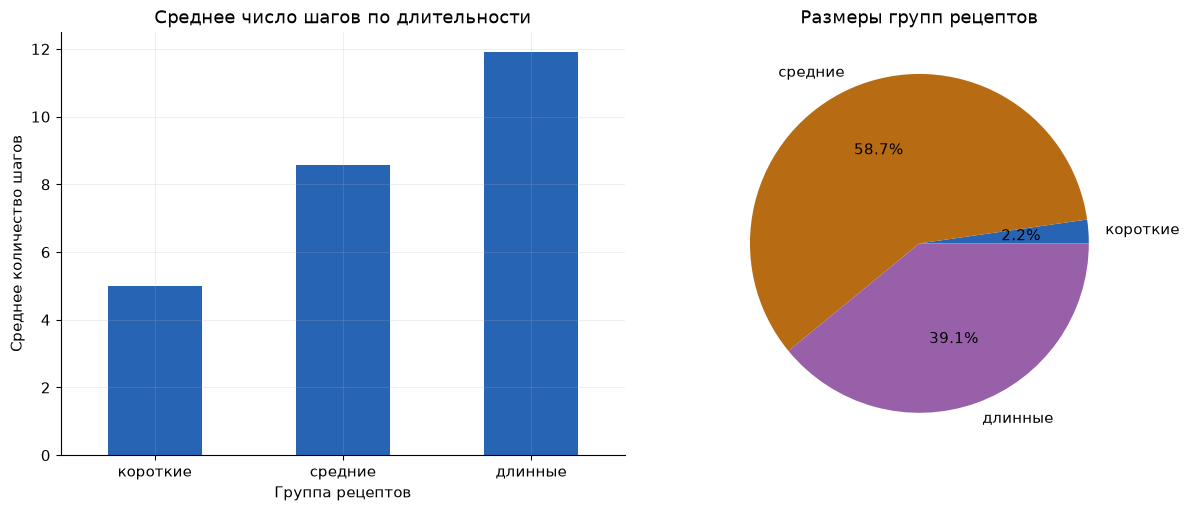

In [24]:
duration_labels = ['короткие', 'средние', 'длинные']
recipes['duration_group'] = pd.cut(recipes['minutes'], [0, 5, 50, np.inf], labels=duration_labels, right=False)
assert recipes['duration_group'].notna().all()
duration_summary = recipes.groupby('duration_group', observed=False).agg(
    mean_steps=('n_steps', 'mean'), recipe_count=('id', 'size'), known_steps=('n_steps', 'count'))
display(duration_summary)
assert duration_summary['recipe_count'].sum() == len(recipes)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
duration_summary['mean_steps'].plot.bar(ax=axes[0], color=COLORS[0], rot=0)
axes[0].set(xlabel='Группа рецептов', ylabel='Среднее количество шагов', title='Среднее число шагов по длительности')
duration_summary['recipe_count'].plot.pie(ax=axes[1], colors=COLORS, autopct='%1.1f%%', ylabel='')
axes[1].set_title('Размеры групп рецептов')
axes[1].grid(False)
plt.show()
plt.close(fig)

**Что проверить и объяснить:** В исходном условии Y назван «Средняя длительность», хотя высота — среднее количество шагов. Эталон исправляет подпись по смыслу. Если нужна буквальная подпись для сдачи, замени ylabel, но поясни несоответствие. `known_steps` показывает фактический знаменатель среднего.

### 3.2. `.plot.hist`: гистограмма рейтингов

Гистограмма показывает распределение: сколько значений попало в каждый интервал. Она нужна для сравнения частоты низких/высоких оценок и формы распределения.

**Как записывать**

```python
df[["rating"]].plot.hist(ax=ax, bins=np.arange(-0.5,6.5,1), density=False, legend=False)
ax.set_xticks(range(6))
```

**Параметры и свойства**

- `bins` — число интервалов или явные границы.
- `density=False` — число наблюдений; `True` нормирует площадь до 1, это не просто процент в столбце.
- `alpha` — прозрачность, `color` — цвет, `legend` — показывать легенду.
- `ax` — область графика; `sharey=True` при создании областей связывает шкалу частот.
- `np.arange(-0.5,6.5,1)` создаёт границы вокруг целых рейтингов 0…5.

**Как это работает**

Число bинов меняет вид гистограммы. Для сравнения лет задавай одни границы и одинаковые шкалы, а также указывай объём данных. Рейтинг 0 в этой лабораторной является значением, а не отсутствием отзыва.

**Частая ошибка:** При разном числе отзывов большая высота столбца может объясняться размером выборки, а не большей долей этой оценки.

**Пример**

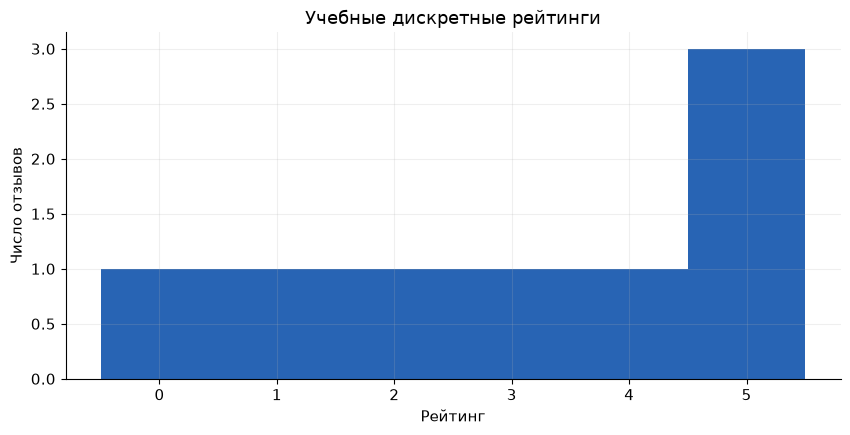

In [25]:
demo_ratings = pd.Series([0, 1, 2, 3, 4, 5, 5, 5], name='rating')
fig, ax = plt.subplots()
demo_ratings.plot.hist(ax=ax, bins=np.arange(-0.5, 6.5, 1), color=COLORS[0])
ax.set(xlabel='Рейтинг', ylabel='Число отзывов', title='Учебные дискретные рейтинги')
ax.set_xticks(range(6))
plt.show()
plt.close(fig)

### Тренировка

Почему рейтинг 0 не следует автоматически выкидывать? Чем сравнение чисел отзывов отличается от сравнения долей?

<details><summary>Подсказка — открой после своей попытки</summary>

Ноль в исходной лабораторной считается настоящим отзывом. Размеры годовых выборок могут различаться.

</details>

In [26]:
# Твоё решение
# Напиши код здесь. Исходные данные и примеры выше можно использовать.

**Эталон и разбор.** Сначала сравни идею решения со своей, затем запусти ячейку ниже.

In [27]:
print('В учебном примере отзывов:', len(demo_ratings))
print('Нулевых рейтингов:', demo_ratings.eq(0).sum())

В учебном примере отзывов: 8
Нулевых рейтингов: 1


**Что проверить и объяснить:** Для сравнения долей нужна нормализация, но исходное задание просит обычные гистограммы.

### ЛР5 · задание 6

6\. Из всего множества отзывов оставьте только те, которые были даны в 2008 и 2009 годах. Воспользовавшись возможностями метода `pd.DataFrame.plot.hist`, постройте 2 гистограммы столбца `rating`. Гистограммы должны быть расположены рядом по горизонтали. Левая гистограмма соотвествует 2008 году, правая - 2009 году. Добавьте общую подпись для рисунка с текстом "Гистограммы рейтинга отзывов в 2008 и 2009 годах". Добейтесь того, чтобы подпись вертикальной оси правого рисунка не "наезжала" на левый рисунок.

<details><summary>Подсказка — открой после своей попытки</summary>

Выбери годы через `.dt.year`. `DataFrame.plot.hist` вызывается отдельно для каждого года с одним набором bins.

</details>

In [28]:
# Твоё решение
# Напиши код здесь. Исходные данные и примеры выше можно использовать.

**Эталон и разбор.** Сначала сравни идею решения со своей, затем запусти ячейку ниже.

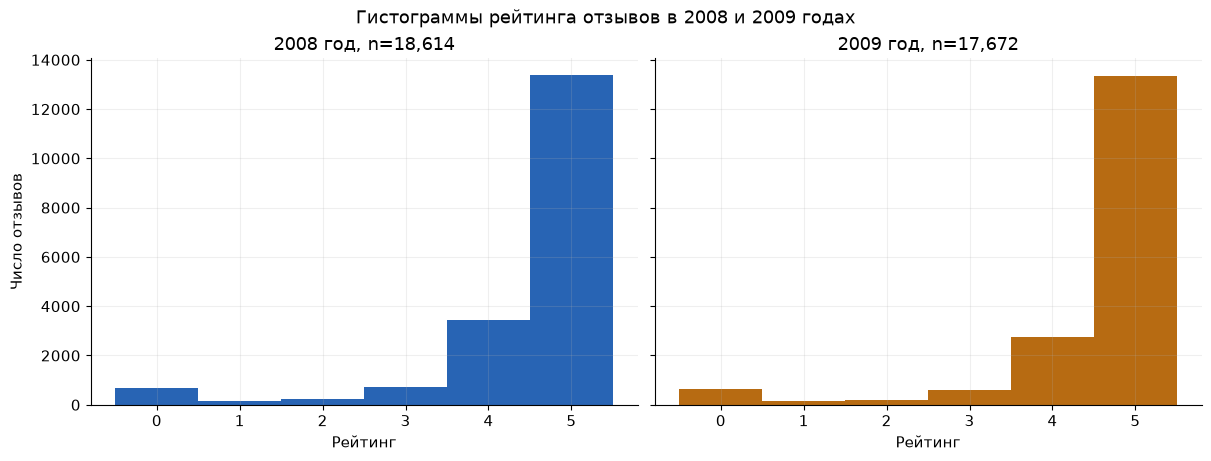

In [29]:
review_year = reviews['date'].dt.year
selected_reviews = reviews.loc[review_year.isin([2008, 2009])].copy()
assert selected_reviews['rating'].between(0, 5).all()
fig, axes = plt.subplots(1, 2, sharey=True, figsize=(12, 4.5), constrained_layout=True)
for ax, year, color in zip(axes, [2008, 2009], COLORS):
    year_reviews = selected_reviews.loc[selected_reviews['date'].dt.year == year]
    year_reviews[['rating']].plot.hist(ax=ax, bins=np.arange(-0.5, 6.5, 1), legend=False, color=color)
    ax.set(xlabel='Рейтинг', ylabel='Число отзывов', title=f'{year} год, n={len(year_reviews):,}')
    ax.set_xticks(range(6))
fig.suptitle('Гистограммы рейтинга отзывов в 2008 и 2009 годах')
plt.show()
plt.close(fig)

**Что проверить и объяснить:** Общая ось Y и одинаковые интервалы обеспечивают сопоставимость. `constrained_layout` оставляет место для подписей; размеры выборок указаны в заголовках.

## Seaborn: задания 7–8

Seaborn принимает таблицу и имена столбцов. `hue` разбивает наблюдения по категориям. Axes-level функции `scatterplot` и `heatmap` рисуют на переданном `ax`; figure-level функции из дополнительной практики создают собственные рисунки.

### 4.1. `sns.scatterplot`: связи и группы

Scatterplot показывает связь двух числовых признаков: одна точка — наблюдение. Seaborn берёт данные из DataFrame по именам столбцов, а категории кодирует цветом или формой.

**Как записывать**

```python
sns.scatterplot(data=df, x="steps", y="ingredients", hue="group", style="group",
                palette={"A":"tab:blue", "B":"tab:orange"}, alpha=0.5, s=30, ax=ax)
```

**Параметры и свойства**

- `data` — таблица; `x`/`y` — имена числовых столбцов.
- `hue` — столбец категории для цвета; `hue_order` — порядок категорий.
- `style` — категория для формы маркера; `size` — переменная для размера точки.
- `palette` — палитра или словарь категория→цвет; `s` — фиксированный размер точки.
- `alpha` — прозрачность от 0 до 1.
- `ax` — готовая область Matplotlib; функция возвращает Axes.

**Как это работает**

Если много наблюдений лежат в одинаковых координатах, они перекрываются. Прозрачность помогает, но не даёт точного счётчика. Перед построением проверь пропуски X и Y; затем отдельно укажи, сколько строк не показано.

**Частая ошибка:** Положительный наклон облака не означает строгую линейную зависимость или причинность. Не кодируй слишком много признаков одновременно.

**Пример**

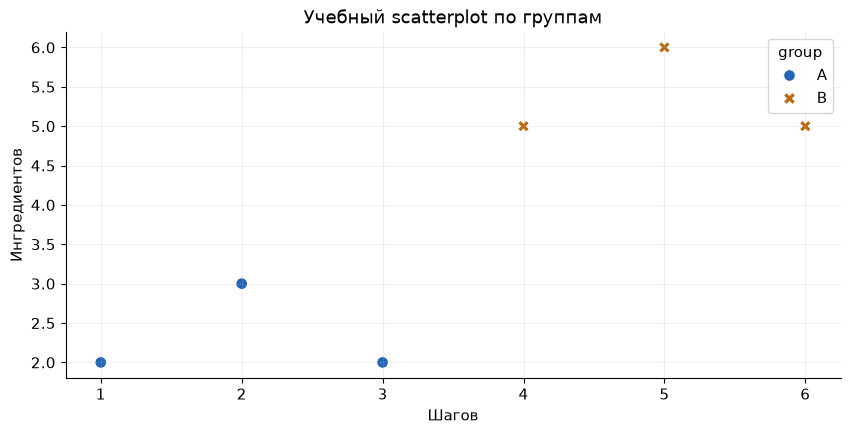

In [30]:
scatter_demo = pd.DataFrame({'steps': [1, 2, 3, 4, 5, 6], 'ingredients': [2, 3, 2, 5, 6, 5],
                            'group': ['A', 'A', 'A', 'B', 'B', 'B']})
fig, ax = plt.subplots()
sns.scatterplot(data=scatter_demo, x='steps', y='ingredients', hue='group', style='group',
                palette={'A': COLORS[0], 'B': COLORS[1]}, ax=ax, s=70)
ax.set(xlabel='Шагов', ylabel='Ингредиентов', title='Учебный scatterplot по группам')
plt.show()
plt.close(fig)

### Тренировка

Посчитай корреляцию steps и ingredients в учебном примере. Объясни, что она не сообщает о причинности.

<details><summary>Подсказка — открой после своей попытки</summary>

`scatter_demo[["steps","ingredients"]].corr()`.

</details>

In [31]:
# Твоё решение
# Напиши код здесь. Исходные данные и примеры выше можно использовать.

**Эталон и разбор.** Сначала сравни идею решения со своей, затем запусти ячейку ниже.

In [32]:
display(scatter_demo[['steps', 'ingredients']].corr())

,steps,ingredients
steps,1.000000,0.837906
ingredients,0.837906,1.000000


**Что проверить и объяснить:** Это только линейная связь в маленьком учебном примере; не переносим её коэффициент на рецепты.

### ЛР5 · задание 7

7\. При помощи пакета `seaborn` постройте диаграмму рассеяния двух столбцов из таблицы `recipes`: `n_steps` и `n_ingredients`. Укажите в качестве группирующей переменной (hue) категориальную длительность рецепта (короткий, средний или длинные; см. задание 5). 

Добавьте заголовок рисунка "Диаграмма рассеяния n_steps и n_ingredients"

Прокомментируйте, наблюдается ли визуально линейная зависимость между двумя этими переменными. Ответ оставьте в виде текстовой ячейки под изображением.

<details><summary>Подсказка — открой после своей попытки</summary>

Используй категорию длительности из задания 5. Исключённые из графика пропуски посчитай явно.

</details>

In [33]:
# Твоё решение
# Напиши код здесь. Исходные данные и примеры выше можно использовать.

**Эталон и разбор.** Сначала сравни идею решения со своей, затем запусти ячейку ниже.

Точек на графике: 13225 Не показано из-за пропусков: 16775


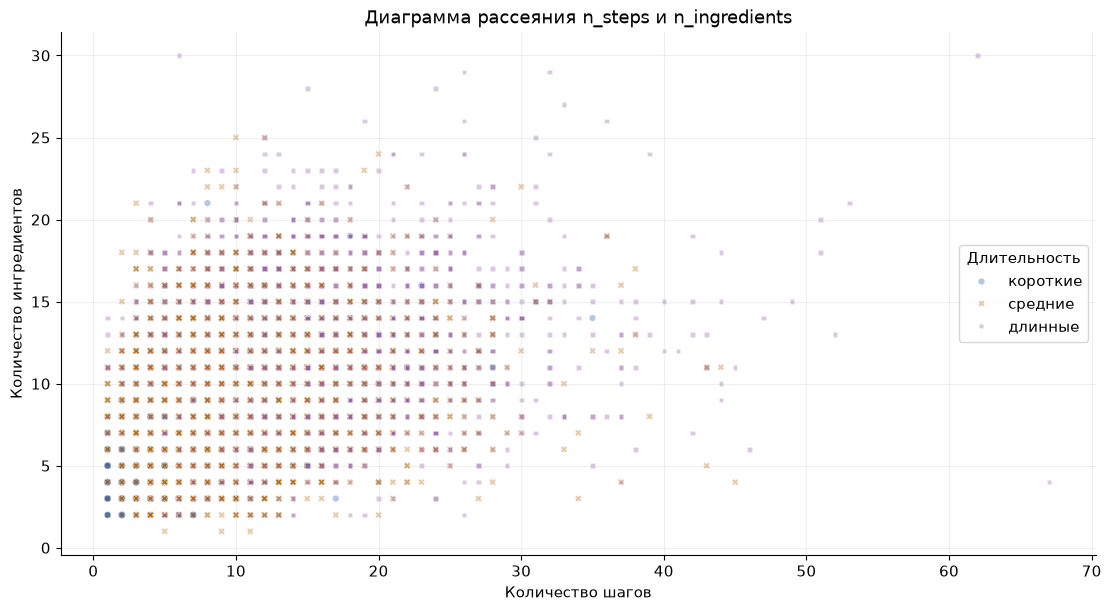

Корреляция Пирсона на показанных точках: 0.412


In [34]:
scatter_data = recipes.dropna(subset=['n_steps', 'n_ingredients', 'duration_group'])
print('Точек на графике:', len(scatter_data), 'Не показано из-за пропусков:', len(recipes) - len(scatter_data))
fig, ax = plt.subplots(figsize=(11, 6), constrained_layout=True)
sns.scatterplot(data=scatter_data, x='n_steps', y='n_ingredients', hue='duration_group',
                hue_order=duration_labels, style='duration_group',
                palette=dict(zip(duration_labels, COLORS)), alpha=0.35, s=22, ax=ax)
ax.set(xlabel='Количество шагов', ylabel='Количество ингредиентов',
       title='Диаграмма рассеяния n_steps и n_ingredients')
ax.legend(title='Длительность')
plt.show()
plt.close(fig)
steps_ingredients_r = scatter_data['n_steps'].corr(scatter_data['n_ingredients'])
print(f'Корреляция Пирсона на показанных точках: {steps_ingredients_r:.3f}')

**Что проверить и объяснить:** Напиши собственный комментарий в следующей Markdown-ячейке. Проверь, насколько широк разброс при одном числе шагов; одного положительного коэффициента недостаточно для «строгой линейной зависимости».

**Место для твоего вывода:** опиши направление связи, разброс и различия групп.

**Пример разбора:** облако имеет тенденцию к росту числа ингредиентов с числом шагов, но при одном числе шагов значения заметно различаются. Это не строгая зависимость вида `y = ax + b`. Коэффициент выше дополняет визуальное наблюдение, но не доказывает причинность. Значения с пропусками не показаны.

### 4.2. `.corr` и `sns.heatmap`: корреляционная матрица

Корреляционная матрица содержит коэффициенты связи каждой пары признаков. Heatmap отображает их цветом, а подписи позволяют прочитать точное значение.

**Как записывать**

```python
corr = df[["minutes","steps","ingredients","rating"]].corr(method="pearson")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="YlOrRd", vmin=-1, vmax=1, square=True, ax=ax)
```

**Параметры и свойства**

- `corr(method="pearson")` измеряет линейную связь от −1 до 1; `spearman` — ранговую.
- `min_periods` у `.corr` задаёт минимум заполненных наблюдений для пары.
- `heatmap(data)` принимает двумерную таблицу коэффициентов.
- `annot=True` пишет значения, `fmt=".2f"` задаёт два знака после точки.
- `cmap` — цветовая карта; `vmin`/`vmax` — фиксированные границы её шкалы.
- `square=True` делает ячейки квадратными; `mask` может скрыть часть матрицы.
- `center=0` полезен с расходящейся картой для отрицательных/положительных связей.

**Как это работает**

По диагонали — связь признака с самим собой, обычно 1. Матрица симметрична. Пропуски исключаются отдельно для каждой пары. После соединения рецептов с отзывами один рецепт может повторяться много раз: это меняет веса наблюдений.

**Частая ошибка:** Корреляция около 0 не исключает нелинейной связи. Палитра не должна заставлять считать слабые различия сильными; здесь `YlOrRd` требуется условием.

**Пример**

In [35]:
display(scatter_demo[['steps', 'ingredients']].corr())

,steps,ingredients
steps,1.000000,0.837906
ingredients,0.837906,1.000000


### Тренировка

Проверь симметричность и диагональ этой маленькой матрицы.

<details><summary>Подсказка — открой после своей попытки</summary>

`np.allclose(corr, corr.T)` и `np.diag(corr)`.

</details>

In [36]:
# Твоё решение
# Напиши код здесь. Исходные данные и примеры выше можно использовать.

**Эталон и разбор.** Сначала сравни идею решения со своей, затем запусти ячейку ниже.

In [37]:
demo_corr = scatter_demo[['steps', 'ingredients']].corr()
assert np.allclose(demo_corr, demo_corr.T)
assert np.allclose(np.diag(demo_corr), 1)
print('Симметрия и диагональ проверены')

Симметрия и диагональ проверены


**Что проверить и объяснить:** Для константного столбца корреляция может быть NaN; единичная диагональ не универсальна для любых данных.

### ЛР5 · задание 8

8\. Объедините две таблицы `recipes` и `reviews` и постройте корреляционную матрицу на основе столбцов "minutes", "n_steps", "n_ingredients" и "rating". При помощи пакета `seaborn` визуализируйте полученную матрицу в виде тепловой карты (heatmap). 

Добавьте в ячейки тепловой карты подписи (значения к-та корреляции). Измените цветовую палитру на `YlOrRd`. 

Добавьте заголовок рисунка "Корреляционная матрица числовых столбцов таблиц recipes и reviews"

<details><summary>Подсказка — открой после своей попытки</summary>

Inner-merge по id/recipe_id, затем ровно четыре числовых столбца. Для подписей — `annot=True`, для палитры — `cmap="YlOrRd"`.

</details>

In [38]:
# Твоё решение
# Напиши код здесь. Исходные данные и примеры выше можно использовать.

**Эталон и разбор.** Сначала сравни идею решения со своей, затем запусти ячейку ниже.

,minutes,n_steps,n_ingredients,rating
minutes,1.000,0.031,-0.006,-0.026
n_steps,0.031,1.000,0.294,-0.019
n_ingredients,-0.006,0.294,1.000,0.003
rating,-0.026,-0.019,0.003,1.000


,minutes,n_steps,n_ingredients,rating
Число наблюдений для каждой пары,,,,
minutes,126696,78818,88055,126696
n_steps,78818,78818,54324,78818
n_ingredients,88055,54324,88055,88055
rating,126696,78818,88055,126696


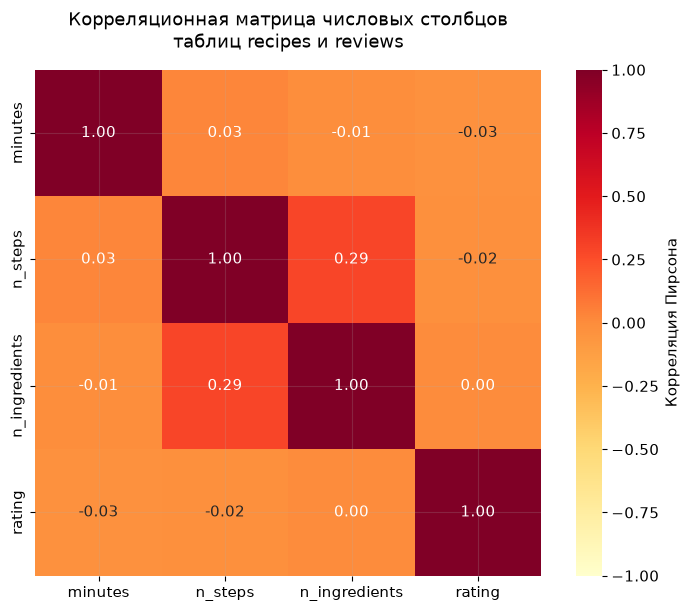

In [39]:
merged = recipes[['id', 'minutes', 'n_steps', 'n_ingredients']].merge(
    reviews[['recipe_id', 'rating']], left_on='id', right_on='recipe_id',
    how='inner', validate='one_to_many')
corr_columns = ['minutes', 'n_steps', 'n_ingredients', 'rating']
correlation = merged[corr_columns].corr()
available = merged[corr_columns].notna().astype(np.int64)
pair_counts = available.T @ available
display(correlation.round(3))
display(pair_counts.rename_axis('Число наблюдений для каждой пары'))
assert np.allclose(correlation, correlation.T, equal_nan=True)
fig, ax = plt.subplots(figsize=(8.5, 6), constrained_layout=True)
sns.heatmap(correlation, annot=True, fmt='.2f', cmap='YlOrRd', vmin=-1, vmax=1,
            square=True, cbar_kws={'label': 'Корреляция Пирсона'}, ax=ax)
ax.set_title('Корреляционная матрица числовых столбцов\nтаблиц recipes и reviews', pad=16)
plt.show()
plt.close(fig)

**Что проверить и объяснить:** Рецепт с большим числом отзывов повторяется чаще: единица анализа здесь — отзыв. Корреляция признаков рецепта взвешивается числом его отзывов. Нули rating учитываются. Пропуски считаются отдельно по парам.

## Дополнительная практика

Следующие блоки углубляют уже разобранные инструменты. Примеры с `sns.load_dataset` требуют интернета; задания с `train_test_split` — scikit-learn, с KDE — SciPy. Сначала мини-лекция по блоку, затем упражнения.

Пример данных:

```python
import matplotlib.pyplot as plt
```

Пример данных:

```python
import numpy as np
```

Пример данных:

```python
import pandas as pd
```

Пример данных:

```python
import seaborn as sns
```

## Блок 1. Устройство matplotlib: Figure и Axes

`subplots(figsize,dpi)` создаёт Figure и Axes. Через `ax` задают данные, подписи и легенду. `fig.savefig(path,dpi,bbox_inches)` сохраняет рисунок, `close(fig)` освобождает его. `figsize*dpi` даёт размер без подрезания полей.

**Пример записи**

```python
fig, ax = plt.subplots(figsize=(8,4))
ax.plot([1,2,3], [2,4,3],label="Ряд")
ax.legend()
```

**Тренировка:** задания ниже используют эти инструменты.

### 1.1: два интерфейса
x = np.linspace(0, 2 * np.pi, 100)
- а) pyplot-стиль: plt.plot(x, np.sin(x)); plt.show()
- б) объектный стиль: fig, ax = plt.subplots(); ax.plot(x, np.sin(x)); plt.show()
Выведи type(fig) и type(ax). Ожидание: Figure и Axes.
Объясни: Figure — «холст/окно», Axes — одна область с осями (не путай с axis).
Почему в рабочем коде и в библиотеках предпочитают объектный стиль?
(явно видно, на какой Axes рисуем; нет скрытого «текущего» состояния)

In [40]:
# Дополнительная практика: твоё решение

### 1.2: размер, dpi и сохранение
fig, ax = plt.subplots(figsize=(8, 4), dpi=100)
Нарисуй sin и cos на одном Axes, сохрани fig.savefig('trig.png', dpi=150, bbox_inches='tight').
Проверь размер картинки в пикселях: figsize * dpi. Ожидание для dpi=150: 1200 x 600 (примерно,
bbox_inches='tight' обрезает поля). Закрой фигуру через plt.close(fig) — зачем? (память в циклах)

In [41]:
# Дополнительная практика: твоё решение

## Блок 2. Базовые типы графиков

`plot` соединяет точки, `scatter` показывает отдельные наблюдения. `bar/barh` сравнивают категории; `hist(bins,density)` — распределение; `boxplot` — медиану и разброс; `errorbar(yerr)` — указанные интервалы. Для std и доверительного интервала нужны разные подписи.

**Пример записи**

```python
bars = ax.bar(["A","B"],[10,20])
ax.bar_label(bars)
```

**Тренировка:** задания ниже используют эти инструменты.

Пример данных:

```python
rng = np.random.default_rng(42)
```

### 2.1: line и scatter
x = np.linspace(0, 10, 50); y = 2 * x + rng.normal(scale=2, size=50)
- а) линия ax.plot(x, y, marker='o', linestyle='--', color='tab:blue')
- б) scatter ax.scatter(x, y, c=y, cmap='viridis', s=40) + fig.colorbar(...)
Чем plot с marker отличается от scatter? (scatter умеет менять размер и цвет каждой точки,
plot быстрее на больших данных)

In [42]:
# Дополнительная практика: твоё решение

### 2.2: bar и barh
cats = ['A', 'B', 'C', 'D']; vals = [23, 17, 35, 29]
- а) вертикальные столбцы ax.bar
- б) горизонтальные ax.barh, отсортированные по убыванию значений
- в) подпиши значения над столбцами: ax.bar_label(bars)
Почему для длинных названий категорий лучше barh?

In [43]:
# Дополнительная практика: твоё решение

### 2.3: hist
data = rng.normal(loc=0, scale=1, size=1000)
- а) ax.hist(data, bins=30)
- б) то же с density=True; проверь, что площадь гистограммы = 1
   (сумма высот * ширина бина, ширина = np.diff(edges)[0])
- в) сравни bins=5, 30, 200. Как число бинов меняет вывод о форме распределения?

In [44]:
# Дополнительная практика: твоё решение

### 2.4: boxplot и errorbar
groups = [rng.normal(m, 1, 200) for m in (0, 1, 2)]
- а) ax.boxplot(groups, tick_labels=['g0', 'g1', 'g2'])  (в старых версиях параметр labels)
   Что показывают: медиана, ящик (Q1–Q3), усы (1.5 * IQR), точки-выбросы?
- б) ax.errorbar([0, 1, 2], [g.mean() for g in groups], yerr=[g.std(ddof=1) for g in groups], fmt='o', capsize=4)

In [45]:
# Дополнительная практика: твоё решение

## Блок 3. Оформление: подписи, легенда, оси, стили

Подписи и единицы задают через `set_xlabel/set_ylabel`, пределы — `set_xlim/set_ylim`, засечки — `set_xticks`. `annotate` добавляет подпись, `axhline` — ориентир, `fill_between` — полосу с явно заданным смыслом. Последовательные, расходящиеся и качественные карты решают разные задачи.

**Пример записи**

```python
ax.set(xlabel="Время, с",ylabel="Скорость, м/с",title="Движение")
ax.grid(alpha=0.2)
```

**Тренировка:** задания ниже используют эти инструменты.

### 3.1: обязательный минимум
Для графика sin и cos из 1.2 добавь: title, xlabel, ylabel, label= у линий + ax.legend(),
ax.grid(alpha=0.3). Правило: на графике без подписей осей и единиц измерения нельзя
ничего понять — проверь каждый свой график по этому чек-листу.

In [46]:
# Дополнительная практика: твоё решение

### 3.2: пределы, ticks, масштаб
- а) ax.set_xlim / ax.set_ylim
- б) ax.set_xticks([0, np.pi, 2*np.pi]) и ax.set_xticklabels(['0', 'π', '2π'])
- в) логарифмическая ось: x = np.logspace(0, 3, 50); ax.plot(x, x**2); ax.set_xscale('log'); ax.set_yscale('log')
   Ожидание: степенная зависимость на log-log — прямая линия. Почему?

In [47]:
# Дополнительная практика: твоё решение

### 3.3: annotate, axhline, fill_between
- а) отметь максимум sin стрелкой: ax.annotate('max', xy=(np.pi/2, 1), xytext=(2, 1.2), arrowprops=dict(arrowstyle='->'))
- б) горизонтальная линия среднего ax.axhline(y.mean(), color='gray', linestyle=':')
- в) доверительная полоса: ax.fill_between(x, y - 1, y + 1, alpha=0.2)

In [48]:
# Дополнительная практика: твоё решение

### 3.4: стили и цвета
print(plt.style.available) — выбери один (например 'seaborn-v0_8-whitegrid' или 'ggplot')
и примени через plt.style.use(...) или with plt.style.context(...).
Сравни цветовые карты для разных данных:
- последовательные ('viridis') — для величин от малого к большому,
- расходящиеся ('coolwarm') — для данных с осмысленным нулём (корреляции),
- качественные ('tab10') — для категорий.
Почему 'jet' (радужная) считается плохим выбором? (не монотонна по яркости, искажает восприятие)

In [49]:
# Дополнительная практика: твоё решение

## Блок 4. Несколько графиков: subplots

`subplots(nrows,ncols,sharex,sharey)` создаёт регулярную сетку. `axes.flat` обходит её. `twinx` добавляет независимую Y, что требует осторожной интерпретации. `subplot_mosaic` задаёт раскладку именованными областями; constrained_layout выделяет место под подписи.

**Пример записи**

```python
fig, axes = plt.subplots(2,2,sharex=True,constrained_layout=True)
for ax in axes.flat:
    ax.set_xlabel("X")
```

**Тренировка:** задания ниже используют эти инструменты.

### 4.1: сетка
fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, constrained_layout=True)
Выведи axes.shape. Ожидание: (2, 2). Нарисуй в каждой ячейке свою функцию (sin, cos, x**2, exp)
и подпиши через ax.set_title. Для чего sharex/sharey? (одинаковый масштаб для сравнения)
Как обойти axes в цикле: for ax in axes.flat.

In [50]:
# Дополнительная практика: твоё решение

### 4.2: две оси Y
Нарисуй на одном Axes температуру (°C) и осадки (мм) за 12 месяцев:
ax2 = ax.twinx(); цвета линий и подписей осей должны совпадать.
Когда twinx вводит в заблуждение? (разные шкалы можно подогнать так, чтобы «показать» корреляцию)

In [51]:
# Дополнительная практика: твоё решение

### 4.3: сложная раскладка
fig, axd = plt.subplot_mosaic([['top', 'top'], ['left', 'right']], figsize=(8, 6))
Нарисуй на 'top' временной ряд, на 'left' гистограмму, на 'right' scatter.
Это удобнее GridSpec для нерегулярных сеток.

In [52]:
# Дополнительная практика: твоё решение

## Блок 5. Матричные данные и связь с NumPy / Pandas

`imshow(array,cmap,origin)` визуализирует матрицу: `upper` направляет строки вниз, `lower` — вверх. `fig.colorbar(image,ax)` показывает шкалу цвета. Pandas `.plot(kind,x,y,ax)` возвращает Axes. Для плотности гистограммы используй density=True и сравнивай площадь, а не сумму высот.

**Пример записи**

```python
image = ax.imshow(np.arange(9).reshape(3,3),cmap="viridis",origin="upper")
fig.colorbar(image,ax=ax)
```

**Тренировка:** задания ниже используют эти инструменты.

### 5.1: imshow
M = rng.random((10, 10))
ax.imshow(M, cmap='viridis'); fig.colorbar(im). Затем np.arange(100).reshape(10, 10)
и убедись, что (0, 0) — левый верхний угол (origin='upper'), строки идут вниз.
Как отобразить матрицу как в математике (ось Y вверх)? (origin='lower')

In [53]:
# Дополнительная практика: твоё решение

### 5.2: график из DataFrame
df = pd.DataFrame({'x': np.arange(10), 'a': rng.random(10), 'b': rng.random(10)})
- а) df.plot(x='x', y=['a', 'b'])  — возвращает Axes. Проверь type(ax).
- б) df.plot(kind='bar', x='x'), df['a'].plot(kind='hist')
- в) передай готовый Axes: df.plot(ax=axes[0])
Вывод: pandas.plot — тонкая обёртка над matplotlib, всё оформление делается через Axes.

In [54]:
# Дополнительная практика: твоё решение

### 5.3: распределения из NumPy (связка с Numpy.py)
Нарисуй гистограмму 10_000 значений rng.normal и поверх — теоретическую плотность
(1/sqrt(2π)) * exp(-x²/2) через ax.plot. Проверь, что при density=True они совпадают по форме.
Затем rng.exponential и rng.uniform — как выглядят их гистограммы?

In [55]:
# Дополнительная практика: твоё решение

## Блок 6. Seaborn: данные и стиль

Seaborn удобно работает с tidy-таблицей: строка — наблюдение, столбец — переменная. `set_theme(style,context,palette)` задаёт оформление. Axes-level функции принимают ax, figure-level (`relplot/displot/catplot`) создают свои области и используют col/row. `load_dataset` требует доступ к демонстрационным данным.

**Пример записи**

```python
sns.scatterplot(data=df,x="x",y="y",hue="group",ax=ax)
```

**Тренировка:** задания ниже используют эти инструменты.

### 6.1: тема и датасеты
sns.set_theme(style='whitegrid', context='notebook', palette='deep')
tips = sns.load_dataset('tips'); выведи tips.shape, tips.head().
Ожидание: (244, 7), столбцы total_bill, tip, sex, smoker, day, time, size.
Seaborn работает с «длинным» (tidy) форматом: одна строка — одно наблюдение, один столбец — одна переменная.
Объясни, чем это отличается от «широкого» формата, где столбцы — это группы.

In [56]:
# Дополнительная практика: твоё решение

### 6.2: axes-level против figure-level
- axes-level (scatterplot, histplot, boxplot, heatmap...) — рисуют на переданном ax=...
  и возвращают Axes; их можно класть в subplots.
- figure-level (relplot, displot, catplot, pairplot, jointplot) — создают свою Figure
  (FacetGrid), принимают col=, row=, hue=, возвращают Grid-объект, ax= не принимают.
Для каждого из них напиши по одному примеру ниже и убедись в разнице типов возвращаемого объекта.

In [57]:
# Дополнительная практика: твоё решение

## Блок 7. Seaborn: распределения и категории

`histplot` показывает интервалы, `kdeplot` — сглаженную оценку плотности, `ecdfplot` — накопленную долю. Для категорий `countplot` считает строки, `barplot(estimator,errorbar)` оценивает статистику, `boxplot/violinplot` показывают разброс. `catplot(col,row,kind)` делит рисунок на группы.

**Пример записи**

```python
sns.barplot(data=df,x="group",y="value",estimator="mean",errorbar=("ci",95),ax=ax)
```

**Тренировка:** задания ниже используют эти инструменты.

### 7.1: распределения
tips = sns.load_dataset('tips')
- а) sns.histplot(tips, x='total_bill', bins=20, kde=True)
- б) sns.histplot(tips, x='total_bill', hue='time', multiple='stack')
- в) sns.kdeplot(tips, x='total_bill', hue='sex', fill=True)
- г) sns.ecdfplot(tips, x='tip')  — как по ECDF прочитать медиану? (где кривая = 0.5)
- д) sns.displot(tips, x='tip', col='time', kind='hist')  (figure-level)
Что видно по распределению total_bill? (правый «хвост», скошенность вправо)

In [58]:
# Дополнительная практика: твоё решение

### 7.2: категориальные графики
- а) sns.countplot(tips, x='day', hue='sex')
- б) sns.boxplot(tips, x='day', y='total_bill')
- в) sns.violinplot(tips, x='day', y='total_bill', hue='sex', split=True)
- г) sns.stripplot / sns.swarmplot поверх boxplot (покажи сами точки, а не только сводку)
- д) sns.barplot(tips, x='day', y='tip', estimator='mean', errorbar='ci') — что значат чёрточки?
   (95% доверительный интервал среднего через bootstrap). Чем barplot отличается от countplot?
Сформулируй: когда boxplot честнее, чем barplot со средним?

In [59]:
# Дополнительная практика: твоё решение

### 7.3: catplot с фасетами
sns.catplot(tips, x='day', y='total_bill', col='time', hue='smoker', kind='box')
Сколько Axes получилось? Достань: g = sns.catplot(...); g.axes.shape, g.fig.
Подпиши g.set_axis_labels('День', 'Счёт, $') и g.set_titles('{col_name}').

In [60]:
# Дополнительная практика: твоё решение

## Блок 8. Seaborn: связи между признаками

`scatterplot` показывает пары, `regplot` добавляет модельную линию, `lmplot(hue)` — линии по группам. `pairplot` сравнивает множество пар, `jointplot` — одну пару вместе с распределениями. `heatmap` показывает матрицу. Общая корреляция может отличаться от корреляций внутри групп.

**Пример записи**

```python
corr = df.select_dtypes("number").corr()
sns.heatmap(corr,annot=True,cmap="coolwarm",center=0,vmin=-1,vmax=1,ax=ax)
```

**Тренировка:** задания ниже используют эти инструменты.

### 8.1: scatter и регрессия
- а) sns.scatterplot(tips, x='total_bill', y='tip', hue='time', size='size', style='smoker')
   Сколько признаков закодировано одним графиком? (5) Не слишком ли много для читателя?
- б) sns.regplot(tips, x='total_bill', y='tip') — линия + доверительная полоса.
- в) sns.lmplot(tips, x='total_bill', y='tip', hue='smoker') — регрессия по группам (figure-level).

In [61]:
# Дополнительная практика: твоё решение

### 8.2: корреляции и heatmap
penguins = sns.load_dataset('penguins')
corr = penguins.select_dtypes('number').corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
Ожидание: диагональ = 1, матрица симметрична. Какие признаки сильнее всего коррелируют?
(flipper_length_mm и body_mass_g ≈ 0.87). Почему cmap расходящийся и center=0?
Покажи только нижний треугольник через mask=np.triu(np.ones_like(corr, dtype=bool)).

In [62]:
# Дополнительная практика: твоё решение

### 8.3: pairplot и jointplot
- а) sns.pairplot(penguins, hue='species') — какие пары признаков лучше всего разделяют виды?
- б) sns.jointplot(penguins, x='bill_length_mm', y='bill_depth_mm', hue='species')
- в) Парадокс Симпсона: в целом bill_length и bill_depth коррелируют отрицательно,
   а внутри каждого вида — положительно. Проверь через sns.regplot по всем данным
   и sns.lmplot с hue='species'. Вывод: агрегат может скрывать обратную связь внутри групп.

In [63]:
# Дополнительная практика: твоё решение

### 8.4: временные ряды и неопределённость
flights = sns.load_dataset('flights')
- а) sns.lineplot(flights, x='year', y='passengers') — что за полоса вокруг линии?
   (агрегация по месяцам: среднее + доверительный интервал)
- б) flights.pivot(index='month', columns='year', values='passengers') -> sns.heatmap
   Какой сезонный паттерн виден? (пик летом, общий рост по годам)

In [64]:
# Дополнительная практика: твоё решение

## Блок 9. Мини-проекты

Разведочный анализ сравнивает распределения, группы и пропуски. Для регрессии сравнивают y_true/y_pred, остатки и RMSE на test. Кривая обучения показывает изменение функции потерь по шагам; log-шкала помогает видеть рост и снижение на порядки. Test не используют для подбора параметров модели.

**Пример записи**

```python
residuals = y_test - predictions
rmse = np.sqrt(np.mean(residuals**2))
ax.scatter(predictions,residuals)
ax.axhline(0,color="gray")
```

**Тренировка:** задания ниже используют эти инструменты.

### 9.1: визуальная разведка Titanic (продолжение уровня 9 из Pandas.py)
titanic = sns.load_dataset('titanic')
Одна Figure 2x3 (subplots + axes-level функции seaborn с ax=...):
1) countplot survived                          — видно дисбаланс классов (≈38% / 62%)
2) barplot survived по sex                     — female ≈ 0.74, male ≈ 0.19
3) barplot survived по pclass, hue='sex'
4) histplot age, hue='survived', multiple='stack' — пропуски age (177) просто не рисуются
5) boxplot fare по pclass, log-шкала по y      — fare сильно скошен вправо
6) heatmap пропусков: sns.heatmap(titanic.isna(), cbar=False) — deck виден почти целиком «жёлтым»
Каждому графику — title, подписи осей. Сохрани в 'titanic_eda.png'.
Письменно: 3 вывода о том, какие признаки информативны, и какой график их показал лучше всего.
Типичная ошибка: смотреть на барплот средних без числа наблюдений в группе — проверь через countplot.

In [65]:
# Дополнительная практика: твоё решение

### 9.2: диагностика линейной регрессии (продолжение 8.3 из Numpy.py)
Тип задачи: регрессия. Метрика: RMSE.
rng = np.random.default_rng(7)
X = rng.normal(size=(200, 2))
y = 5 + 3 * X[:, 0] - 2 * X[:, 1] + rng.normal(scale=0.1, size=200)
Обучи модель по нормальному уравнению (как в Numpy.py 8.3, split 160/40) и построй Figure 1x3:
1) y_true против y_pred на test + диагональ y = x (хорошая модель — точки на диагонали)
2) остатки (y_true - y_pred) против y_pred: sns.residplot или scatter + axhline(0)
   — без структуры, облако вокруг нуля; изгиб или «воронка» = модель не подходит
3) гистограмма остатков с kde — примерно нормальная, центр около 0
Затем замени y на y + 2 * X[:, 0] ** 2 (нелинейность), не меняя модель, и пересчитай графики.
Что изменилось на графике остатков? Это и есть смысл диагностики: метрика RMSE выросла,
а график показывает ПОЧЕМУ.

In [66]:
# Дополнительная практика: твоё решение

### 9.3: кривая обучения (loss curve) на чистом NumPy
Градиентным спуском подбери w для задачи из 9.2 (X с единичным столбцом):
w -= lr * (2 / n) * Xtr.T @ (Xtr @ w - ytr), 200 шагов, lr = 0.1.
Запоминай MSE на train и на test на каждом шаге. Построй обе кривые на одном Axes
(ось Y в log-масштабе). Ожидание: обе быстро падают и выходят на плато около 0.01 (шум 0.1²).
Попробуй lr = 1.5 — что произойдёт? (расходимость, MSE растёт; на log-оси это хорошо видно)
Если test заметно выше train — переобучение; для линейной модели на 160 точках его не ждём.

In [67]:
# Дополнительная практика: твоё решение